# Lab 02 — Supervised learning I: regression, classification, and the workflow

*A regression problem, two classification problems, and saved models at the end*

**Goal.** Fit and read a linear regression on messy listings, validate a classifier in date order, compare classifiers fairly, choose a decision threshold on purpose, tune with cross-validation on training data only, test once, and save the final models as files that can be loaded and used.

**Data.** `all_datasets/supervised/used_cars/used_cars.zip`, `all_datasets/supervised/hotel_bookings/hotel_bookings.zip` and `all_datasets/supervised/telco_customer_churn/telco_customer_churn.csv`

**Reading.** Chapters 10 to 14: how supervised learning works, evaluation, training and model selection, linear models.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab02_supervised_workflow/lab02_supervised_workflow_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab02_supervised_workflow/lab02_supervised_workflow_worked.py`.

**Evidence.** `results/lab02/` — `metrics.csv`, the monthly cancellations and the figures; `models/` gets the churn model with its card and the used-car price model

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Tidy the car listings, predict prices, read the coefficients and the residuals | 2–5 |
| B | Validate hotel cancellations in date order, and see what a shuffled split hides | 6–8 |
| C | Beat a baseline, read probabilities, and choose a threshold by cost | 9–12 |
| D | Tune the churn model with cross-validation, then open the test set once | 13–14 |
| E | Save the models with a card, reload them and use them | 15–16 |
| Finish | Save the evidence; then model log prices and write an overbooking memo | 17–19 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab02/`, and saved models to `models/`.

### Question 1 — Setup

**Read the code.**

- The first three steps are the same in every lab: the course helper, the libraries, and the three folders.
- `joblib` saves a fitted model to a file and loads it back, and `json` writes the model card.
- The metrics are imported in two groups: those for numbers (regression) and those for classes (classification), together with the tools that draw their curves.
- `make_preprocess` is Lab 1's helper, unchanged: median fill and scaling for number columns, most-frequent fill and one-hot encoding for text columns.

**Read the code.**

- The first three steps are the same in every lab: the course helper, the libraries, and the three folders.
- `joblib` saves a fitted model to a file and loads it back, and `json` writes the model card.
- The metrics are imported in two groups: those for numbers (regression) and those for classes (classification), together with the tools that draw their curves.
- `make_preprocess` is Lab 1's helper, unchanged: median fill and scaling for number columns, most-frequent fill and one-hot encoding for text columns.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import json
import joblib                                                      # save and load fitted models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# metrics for numbers (regression) ...
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# ... and for classes (classification), with their plots
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, precision_score, recall_score, roc_auc_score)
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab02")

# 4. One helper used in every part, the same as in Lab 1.
def make_preprocess(num_cols, cat_cols):
    """Prepare a table: fill and scale the number columns, fill and one-hot encode the text columns."""
    numbers = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categories = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", numbers, num_cols), ("cat", categories, cat_cols)])

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab02/ and models/


## Part A — Regression: ordinary least squares versus ridge

**Goal.** Tidy real listings, predict used-car prices with a straight-line model, read its coefficients, and see where it fails.

*Questions 2–5 · Data: used-car listings from Cars.com*

### Question 2 — Read the car listings, tidy them, and split

150,000 car listings collected from Cars.com in October 2026, new and used. Each row is one car with a numeric label, `price_usd`, so this is regression. Three fixed rules, chosen before any model, keep used cars with a believable price ($1,000 to $200,000) and a real odometer reading. Sellers also type the same thing many ways, so `tidy()` maps the spellings of drivetrain and fuel to a few groups. Two models share the pipeline and the split; the only difference is ridge's penalty on large coefficients. The car's `model` (F-150, Camry and over a thousand others) is kept aside for now, and a Your-turn task brings it in.

**Read the code.**

- `low_memory=False` lets pandas read the whole file before deciding each column's type, which avoids a warning on columns of mixed content.
- The filter joins three masks with `&`: used cars, a price from 1,000 to 200,000 dollars (`between` includes both ends), and more than 100 miles on the clock. `.copy()` makes the result an independent table, so that adding columns to it is safe.
- `tidy` lower-cases the text and tests it against each pattern with `str.contains`; a `|` inside a pattern means "or". `np.select` then assigns the first group whose pattern matched, and a listing that matches nothing gets a gap.
- `(2026 - used["year"]).clip(lower=0)` is the car's age, with next year's models counted as 0.
- `train_test_split(X, y, test_size=0.20, random_state=42)` keeps a fifth of the listings for validation.

In [2]:
cars = pd.read_csv(DATA / "supervised/used_cars/used_cars.zip", low_memory=False)
print("shape:", cars.shape)
print(cars["stock_type"].value_counts().to_string())

# Fixed cleaning rules, decided before any model: used cars, a believable price, a real odometer reading.
used = cars[(cars["stock_type"] == "Used")
            & cars["price_usd"].between(1_000, 200_000)
            & (cars["mileage_miles"] > 100)].copy()
print(f"used listings kept: {len(used):,} of {(cars['stock_type'] == 'Used').sum():,}")

# Sellers type the same thing many ways ("AWD", "All-wheel Drive", "All Wheel Drive" ...):
# map them to a few groups.
def tidy(column, groups):
    """Each group is matched by a pattern in the lower-case text; first match wins, no match is a gap."""
    text = column.str.lower()
    matches = [text.str.contains(pattern, na=False) for pattern in groups.values()]
    return pd.Series(np.select(matches, list(groups), default=None), index=column.index)

print("spellings before tidying: drivetrain", used["drivetrain"].nunique(),
      " fuel", used["fuel"].nunique())
used["drive"] = tidy(used["drivetrain"], {"AWD": "all|awd", "4WD": "four|4wd|4x4",
                                          "FWD": "front|fwd", "RWD": "rear|rwd"})
used["fuel_type"] = tidy(used["fuel"], {"plug-in hybrid": "plug", "hybrid": "hybrid|mild",
                                        "electric": "electric", "diesel": "diesel",
                                        "flex fuel": "flex|e85", "gasoline": "gas|petrol|unleaded"})
print(used["drive"].value_counts(dropna=False).to_dict())
print(used["fuel_type"].value_counts(dropna=False).to_dict())

# Age in years when the listings were collected, October 2026; next year's models count as new.
used["age"] = (2026 - used["year"]).clip(lower=0)

num_cols = ["age", "mileage_miles"]
cat_cols = ["make", "body_type", "drive", "fuel_type"]
X = used[num_cols + cat_cols + ["model"]]            # model is kept aside for a Your-turn task
y = used["price_usd"]

# A random 80/20 split: the listings were all collected on one day, so there is no time order to respect.
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.20, random_state=42)
print(len(X_train), "listings to train on and", len(X_valid), "to validate")

shape: (150000, 19)
stock_type
Used    79262
New     70738
used listings kept: 77,646 of 79,262
spellings before tidying: drivetrain 21  fuel 31
{'AWD': 28787, 'FWD': 18290, '4WD': 17310, 'RWD': 9008, None: 4251}
{'gasoline': 63296, None: 5474, 'electric': 3007, 'hybrid': 2986, 'diesel': 2160, 'flex fuel': 594, 'plug-in hybrid': 129}
62116 listings to train on and 15530 to validate


### Question 3 — Fit OLS and ridge

Three scores per model. MAE is the typical miss in dollars. RMSE weights big misses more, so when it is much larger than MAE a few predictions are badly wrong. $R^2$ is the share of the label's variation the model explains. Always guessing the training mean is the baseline both must beat.

**Read the code.**

- `np.full(len(y_valid), y_train.mean())` is the baseline: the training mean, repeated once for every validation car.
- The dictionary `estimators` holds the two models, and the loop gives both the identical preparation.
- `model.fit(X_train, y_train)` learns from the training listings, and `model.predict(X_valid)` prices the listings it has not seen.
- MAE is the average miss in dollars. RMSE squares the misses before averaging, so large misses count for more, and `np.sqrt` brings the result back to dollars. R2 is the share of the variation in price that the model explains.

In [3]:
# The baseline any model must beat: predict the average training price for every car.
baseline = np.full(len(y_valid), y_train.mean())
print("always the training mean: MAE", round(mean_absolute_error(y_valid, baseline)))

# Two models, the same preparation: plain least squares, and ridge, which penalizes large coefficients.
estimators = {
    "linear regression": LinearRegression(),
    "ridge": Ridge(alpha=10.0),
}
fitted, predictions = {}, {}
for name, estimator in estimators.items():
    model = Pipeline([("preprocess", make_preprocess(num_cols, cat_cols)), ("model", estimator)])
    model.fit(X_train, y_train)
    fitted[name] = model
    predictions[name] = pred = model.predict(X_valid)
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_valid, pred)))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_valid, pred))))
    print("R2:", round(r2_score(y_valid, pred), 3))

always the training mean: MAE 15408

linear regression
MAE: 9009
RMSE: 14336
R2: 0.575



ridge
MAE: 9062
RMSE: 14427
R2: 0.569


### Question 4 — Read the coefficients

A linear model is readable: each coefficient is the change in predicted price for a one-unit change in that feature, the others held fixed. The two numeric columns were standardized, so one unit is one standard deviation. Every make gets its own one-hot coefficient, and the cell counts the training listings behind each one.

**Read the code.**

- `get_feature_names_out()` names the prepared columns, and `coef_` holds one coefficient for each. Pairing them in a `pd.Series` lets you look a coefficient up by name.
- The number columns were scaled, so their coefficients are dollars per standard deviation. The first `print` shows how large one standard deviation is.
- `coefs.index.str.startswith("cat__make_")` picks the one-hot columns of `make`, and `removeprefix` strips the prefix to leave the make's name.
- `X_train["make"].value_counts()` counts the listings behind each coefficient. A coefficient that rests on a handful of cars is not to be trusted, so `by_make[by_make["listings"] >= 500]` keeps the well-supported ones.

one standard deviation: {'age': 5.6, 'mileage_miles': 47396.4}
num__age             -3302.0
num__mileage_miles   -8553.0
the four largest:
              coefficient  listings
McLaren          76900.0        16
Ferrari          82800.0        18
Lancia           83000.0         1
Lamborghini     115700.0        14
30 makes have 500 listings or more, for example: {'Porsche': 26300.0, 'Toyota': -11600.0, 'Ford': -13100.0, 'Mitsubishi': -26800.0}


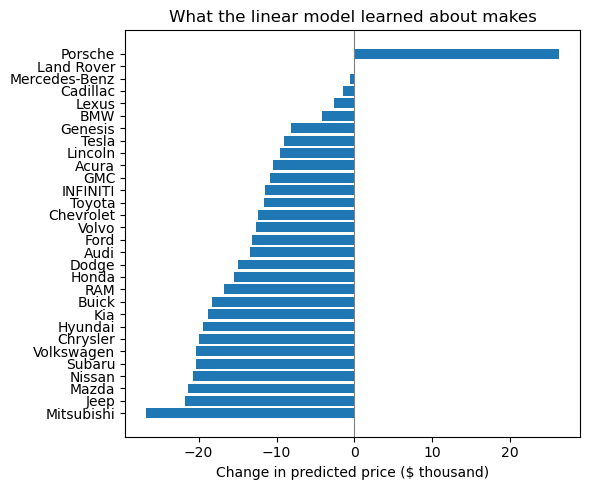

In [4]:
# One coefficient per prepared column: the change in predicted price for a one-unit change in that column
# (one standard deviation, for the scaled number columns).
linear = fitted["linear regression"]
column_names = linear.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linear.named_steps["model"].coef_, index=column_names)
print("one standard deviation:", {c: round(X_train[c].std(), 1) for c in num_cols})
print(coefs[["num__age", "num__mileage_miles"]].round(0).to_string())

# One coefficient per make. How many training listings stand behind each one?
makes = coefs[coefs.index.str.startswith("cat__make_")].rename(lambda c: c.removeprefix("cat__make_"))
by_make = pd.DataFrame({"coefficient": makes.round(-2),
                        "listings": X_train["make"].value_counts()}).sort_values("coefficient")
print("the four largest:\n", by_make.tail(4).to_string())
common = by_make[by_make["listings"] >= 500]             # makes with enough listings to trust
print(len(common), "makes have 500 listings or more, for example:",
      common.loc[["Porsche", "Toyota", "Ford", "Mitsubishi"], "coefficient"].to_dict())

plt.figure(figsize=(6, 5))
plt.barh(common.index, common["coefficient"] / 1000)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Change in predicted price ($ thousand)")
plt.title("What the linear model learned about makes")
plt.tight_layout()
plt.savefig(RESULTS / "what_the_linear_model_learned.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 5 — Plot the residuals

Two diagnostic plots for the ridge model. A good residual plot is a shapeless band around zero. Any shape is something the model failed to use.

**Read the code.**

- A residual is the asking price minus the predicted price.
- `pd.qcut(ridge_pred, 4, labels=[...])` cuts the predictions into four groups of equal size, from the cheapest to the dearest.
- `groupby(quarter).std()` then measures how widely the residuals scatter inside each group.
- The left chart plots the prediction against the truth, with a dashed line where the two would be equal. The right chart plots the residual against the prediction: a fan shape means the misses grow with the price.

spread of the residuals (standard deviation) by quarter of predicted price:
cheapest     9172.0
second       8125.0
third       10943.0
dearest     23079.0
predicted prices below zero: 377


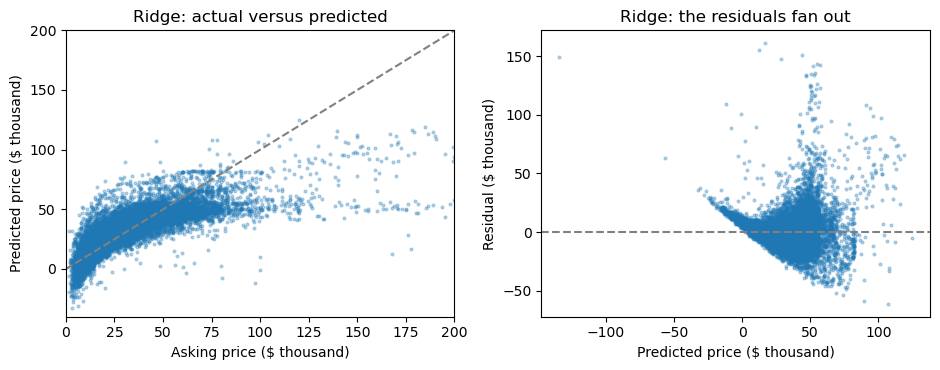

In [5]:
ridge_pred = predictions["ridge"]
residual = y_valid.to_numpy() - ridge_pred           # positive: the car is listed for more than predicted

# Split the predictions into four equal-sized groups, cheapest to dearest, and compare the misses.
quarter = pd.qcut(ridge_pred, 4, labels=["cheapest", "second", "third", "dearest"])
print("spread of the residuals (standard deviation) by quarter of predicted price:")
print(pd.Series(residual).groupby(quarter, observed=True).std().round(0).to_string())
print("predicted prices below zero:", int((ridge_pred < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
axes[0].scatter(y_valid / 1e3, ridge_pred / 1e3, s=4, alpha=0.3)
axes[0].plot([0, 200], [0, 200], linestyle="--", color="grey")
axes[0].set_xlim(0, 200)
axes[0].set_ylim(-40, 200)
axes[0].set_xlabel("Asking price ($ thousand)")
axes[0].set_ylabel("Predicted price ($ thousand)")
axes[0].set_title("Ridge: actual versus predicted")
axes[1].scatter(ridge_pred / 1e3, residual / 1e3, s=4, alpha=0.3)
axes[1].axhline(0, linestyle="--", color="grey")
axes[1].set_xlabel("Predicted price ($ thousand)")
axes[1].set_ylabel("Residual ($ thousand)")
axes[1].set_title("Ridge: the residuals fan out")
plt.tight_layout()
plt.savefig(RESULTS / "ridge_residual_plot.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** 77,646 of the 79,262 used listings pass the three rules, and tidying turns 21 spellings of drivetrain and 31 of fuel into 4 and 6 groups. Linear regression misses by \$9,009 on a typical car (RMSE \$14,336), against \$15,408 for always guessing the training mean, and explains 57.5% of the variation in price; ridge (alpha 10) is no better, at \$9,062. One standard deviation of mileage, about 47,000 miles, takes \$8,553 off the price, and one of age, 5.6 years, another \$3,302, the others held fixed. The largest make coefficients belong to Lamborghini, Lancia, Ferrari and McLaren, but Lancia's rests on a single listing: a rare category gets a confident-looking number from almost no evidence. The residuals fan out, from a spread of \$9,172 in the cheapest quarter of predictions to \$23,079 in the dearest, and 377 cars get a negative price. One straight surface cannot fit a \$5,000 hatchback and a \$150,000 sports car equally well.

**Checkpoint: before you move on**

- Linear regression misses by \$9,009 on average, against \$15,408 for always guessing the mean; ridge is no better.
- The residual spread grows from \$9,172 on the cheapest quarter of predictions to \$23,079 on the dearest, and 377 cars get a negative price.

## Part B — Classification in time: validate in date order

**Goal.** Validate a cancellation model the way a hotel would use it: train on past arrivals, score future ones.

*Questions 6–8 · Data: hotel bookings*

### Question 6 — Split the bookings in date order

Lab 1 scored its hotel model on a shuffled split. A hotel, though, always predicts bookings for dates that have not happened yet, from bookings that already have. So the rows are sorted by arrival date, Lab 1's five engineered columns are rebuilt, and arrivals up to the end of 2016 train while the eight months of 2017 validate.

**Read the code.**

- The arrival date is rebuilt from its three columns, as in Lab 1, and `sort_values("arrival_date", kind="stable")` puts the bookings in date order. A stable sort keeps bookings of the same day in their original order, so the result is the same on every machine.
- The five engineered columns are Lab 1's.
- `(hotels["arrival_date"] < "2017-01-01").to_numpy()` is a mask for the bookings that arrive before 2017. `X_h[in_train]` takes them for training, and `X_h[~in_train]` takes the rest: `~` flips a mask.
- The loop prints the date range, the size and the cancellation rate of each part.

In [6]:
hotels = pd.read_csv(DATA / "supervised/hotel_bookings/hotel_bookings.zip")
text_date = (hotels["arrival_date_year"].astype(str) + "-" + hotels["arrival_date_month"]
             + "-" + hotels["arrival_date_day_of_month"].astype(str))
hotels["arrival_date"] = pd.to_datetime(text_date, format="%Y-%B-%d")
hotels = hotels.sort_values("arrival_date", kind="stable").reset_index(drop=True)

# Lab 1's five engineered columns, and its feature lists.
children = hotels["children"].fillna(0).astype(int)
hotels["total_nights"] = hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]
hotels["total_guests"] = hotels["adults"] + children + hotels["babies"]
hotels["with_children"] = ((children + hotels["babies"]) > 0).astype(int)
hotels["log_lead_time"] = np.log1p(hotels["lead_time"])
hotels["cancelled_before"] = (hotels["previous_cancellations"] > 0).astype(int)
h_num = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
         "previous_cancellations", "previous_bookings_not_canceled", "adr", "required_car_parking_spaces",
         "total_of_special_requests", "total_nights", "total_guests", "with_children", "log_lead_time",
         "cancelled_before"]
h_cat = ["hotel", "meal", "market_segment", "deposit_type", "customer_type"]
X_h = hotels[h_num + h_cat]
y_h = hotels["is_canceled"]

# Split in date order: arrivals up to the end of 2016 train, arrivals in 2017 validate.
in_train = (hotels["arrival_date"] < "2017-01-01").to_numpy()
Xh_train, Xh_valid = X_h[in_train], X_h[~in_train]
yh_train, yh_valid = y_h[in_train], y_h[~in_train]
for label, part in [("train", hotels[in_train]), ("valid", hotels[~in_train])]:
    print(f"{label}: {part['arrival_date'].min().date()} to {part['arrival_date'].max().date()}, "
          f"{len(part):,} bookings, {part['is_canceled'].mean():.1%} cancelled")

train: 2015-07-01 to 2016-12-31, 78,703 bookings, 36.2% cancelled
valid: 2017-01-01 to 2017-08-31, 40,687 bookings, 38.7% cancelled


### Question 7 — Score one model on two splits

The same logistic regression as Lab 1, fitted twice: once on a shuffled 75/25 split, once on the date split. Only the split differs, so any gap between the two scores is what the shuffle was hiding.

**Read the code.**

- `cancellation_model()` returns a fresh, unfitted pipeline every time it is called, so the two fits cannot interfere with each other.
- The first fit uses a shuffled, stratified split, as Lab 1 did. The second uses the date split of Question 6.
- `predict_proba(...)[:, 1]` is the predicted chance of cancelling, and `roc_auc_score` measures how well it ranks the bookings.

In [7]:
def cancellation_model():
    """Lab 1's model: the preparation and a logistic regression, in one pipeline."""
    return Pipeline([("preprocess", make_preprocess(h_num, h_cat)),
                     ("model", LogisticRegression(max_iter=3000))])

# The same model scored two ways: on a shuffled split, as in Lab 1, and on the date split.
Xr_train, Xr_valid, yr_train, yr_valid = train_test_split(X_h, y_h, test_size=0.25, random_state=42,
                                                          stratify=y_h)
shuffled = cancellation_model().fit(Xr_train, yr_train)
print("shuffled split, ROC AUC:    ",
      round(roc_auc_score(yr_valid, shuffled.predict_proba(Xr_valid)[:, 1]), 3))

dated = cancellation_model().fit(Xh_train, yh_train)
prob_h = dated.predict_proba(Xh_valid)[:, 1]          # each 2017 booking's predicted chance of cancelling
print("date split (2017), ROC AUC: ", round(roc_auc_score(yh_valid, prob_h), 3))

shuffled split, ROC AUC:     0.858


date split (2017), ROC AUC:  0.824


### Question 8 — Compare the months

Averaging the predicted probabilities over each month of arrival gives the share of bookings the model expected to cancel; the actual share sits beside it. Months before 2017 were seen in training, the months after were not.

**Read the code.**

- `dt.to_period("M")` turns each arrival date into its month, such as `2017-03`.
- `y_h.groupby(month).mean()` is the share actually cancelled in each month. The second column is the mean predicted probability over the same months.
- `monthly.loc["2016-12":]` keeps the rows from December 2016 onwards, and `.T` prints the months as columns.
- `ax.axvline(...)` marks where the validation months begin.

arrival_date  2016-12  2017-01  2017-02  2017-03  2017-04  2017-05  2017-06  2017-07  2017-08
actual          0.362    0.340    0.325    0.336    0.435    0.438    0.432    0.373    0.369
predicted       0.296    0.303    0.291    0.346    0.406    0.412    0.420    0.361    0.346


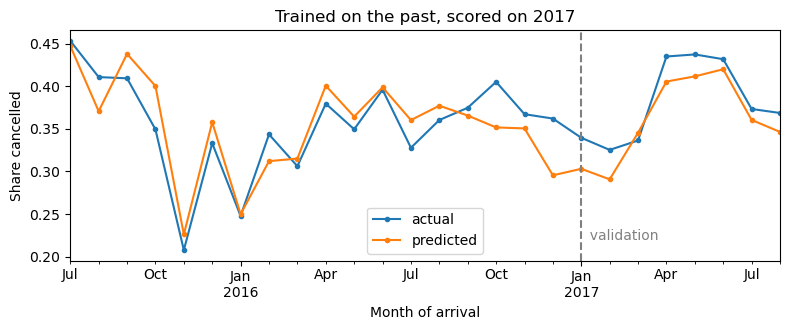

In [8]:
# Month by month: the share of bookings that cancelled, and the share the model expected.
month = hotels["arrival_date"].dt.to_period("M")
monthly = pd.DataFrame({
    "actual": y_h.groupby(month).mean(),
    "predicted": pd.Series(dated.predict_proba(X_h)[:, 1]).groupby(month).mean(),
})
print(monthly.loc["2016-12":].round(3).T.to_string())

ax = monthly.plot(figsize=(8, 3.4), marker="o", markersize=3)
ax.axvline(pd.Period("2017-01", "M"), color="grey", linestyle="--")
ax.text(pd.Period("2017-01", "M"), 0.22, "  validation", color="grey")
ax.set_xlabel("Month of arrival")
ax.set_ylabel("Share cancelled")
ax.set_title("Trained on the past, scored on 2017")
plt.tight_layout()
plt.savefig(RESULTS / "trained_on_the_past_scored_on_2017.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** 78,703 bookings arrive between July 2015 and December 2016, 36.2% of them cancelled; the 40,687 arrivals of 2017 cancelled more often, 38.7%. The same model scores ROC AUC 0.858 on a shuffled split but 0.824 on 2017: the shuffle let it train on bookings from the very weeks it was tested on. Month by month, the model follows the training period closely and then under-predicts the new year, expecting 30.3% cancellations in January 2017 against 34.0% and about 41% in April to June against 43 to 44%. The world it learned from had moved on, and only a split in date order shows it.

**Checkpoint: before you move on**

- Training arrivals end on 31 December 2016; the 40,687 arrivals of 2017 are the validation set.
- The same model scores ROC AUC 0.858 shuffled and 0.824 in date order.

## Part C — Classification: baselines, probabilities, and the threshold

**Goal.** Beat a baseline, read predicted probabilities, and choose a threshold by what each error costs.

*Questions 9–12 · Data: hotel bookings, split in date order*

### Question 9 — Set a baseline and compare classifiers on 2017

The date split from Part B, and two classifiers with the same preparation. Logistic regression is the simple, readable reference; a random forest is the more flexible challenger. Accuracy counts correct decisions at the default 0.5 cutoff; ROC AUC judges how well the model *ranks* bookings, independent of any cutoff. A hotel would act on a flagged booking by reselling its room, so precision answers *when the model says a booking will cancel, how often is it right?*

**Read the code.**

- `1 - yh_valid.mean()` is the accuracy of always answering "kept".
- The loop fits two classifiers with the same preparation. `n_estimators=300` grows 300 trees, `min_samples_leaf=5` stops a tree from isolating single bookings, and `n_jobs=-1` uses every processor core.
- `pipe.predict` answers yes or no at a threshold of 0.5 and feeds the accuracy. `pipe.predict_proba` gives probabilities and feeds the ROC AUC.
- The second loop turns the logistic model's probabilities into decisions at three thresholds with `prob_h >= threshold`, and scores each set of decisions with precision and recall.

majority-class baseline accuracy: 0.613


logistic       accuracy=0.764 roc_auc=0.824


random_forest  accuracy=0.770 roc_auc=0.841
threshold 0.30: precision=0.61 recall=0.77
threshold 0.50: precision=0.78 recall=0.55
threshold 0.70: precision=0.96 recall=0.29


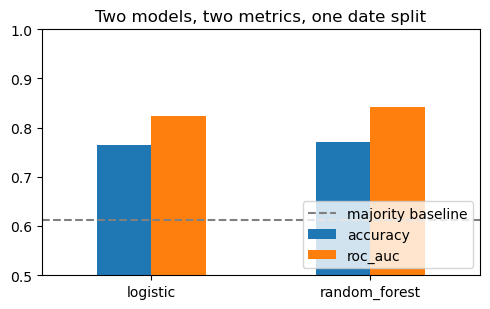

In [9]:
print("majority-class baseline accuracy:", round(1 - yh_valid.mean(), 3))

# Two classifiers with the same preparation, trained on 2015-2016 and scored on 2017, two ways.
classifiers = {
    "logistic": LogisticRegression(max_iter=3000),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1),
}
scores, fitted_h = {}, {}
for name, estimator in classifiers.items():
    pipe = Pipeline([("preprocess", make_preprocess(h_num, h_cat)), ("model", estimator)])
    pipe.fit(Xh_train, yh_train)
    fitted_h[name] = pipe
    accuracy = accuracy_score(yh_valid, pipe.predict(Xh_valid))                   # decisions at 0.5
    auc = roc_auc_score(yh_valid, pipe.predict_proba(Xh_valid)[:, 1])             # the ranking
    scores[name] = {"accuracy": accuracy, "roc_auc": auc}
    print(f"{name:14s} accuracy={accuracy:.3f} roc_auc={auc:.3f}")

# The logistic model, three decision rules: "will cancel" when the probability reaches the threshold.
for threshold in [0.30, 0.50, 0.70]:
    flagged = (prob_h >= threshold).astype(int)
    print(f"threshold {threshold:.2f}: precision={precision_score(yh_valid, flagged):.2f} "
          f"recall={recall_score(yh_valid, flagged):.2f}")

pd.DataFrame(scores).T.plot.bar(figsize=(5, 3.2), ylim=(0.5, 1.0), rot=0)
plt.axhline(1 - yh_valid.mean(), linestyle="--", color="grey", label="majority baseline")
plt.title("Two models, two metrics, one date split")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "two_models_two_metrics_one_date_split.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 10 — Plot the cancellation probabilities

The logistic model gives every 2017 booking a probability of cancelling. Plotting those probabilities separately for the bookings that were kept and those that were cancelled shows what a threshold does: it is a vertical line, and every booking to its right is treated as a likely cancellation, so its room can be resold.

**Read the code.**

- `(prob_h > 0.3) & (prob_h < 0.7)` marks the bookings the model is unsure about, and its mean is their share.
- `prob_h[yh_valid == 0]` selects the probabilities of the bookings that were in fact kept, and the second histogram does the same for the cancelled ones. `alpha=0.6` lets the two show through each other.
- Each `axvline` draws one threshold.

share of 2017 bookings scored between 0.3 and 0.7: 0.374


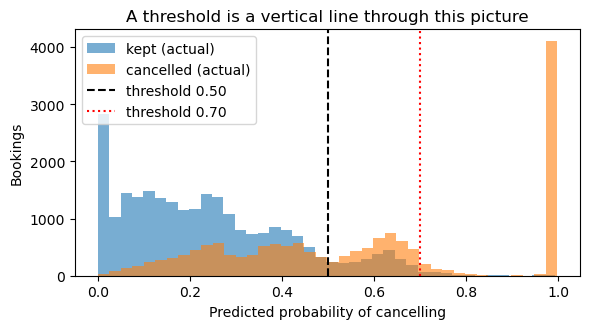

In [10]:
# The logistic model's probabilities for the 2017 bookings, drawn separately for kept and cancelled ones.
uncertain = (prob_h > 0.3) & (prob_h < 0.7)
print("share of 2017 bookings scored between 0.3 and 0.7:", round(uncertain.mean(), 3))

plt.figure(figsize=(6, 3.4))
plt.hist(prob_h[yh_valid == 0], bins=40, alpha=0.6, label="kept (actual)")
plt.hist(prob_h[yh_valid == 1], bins=40, alpha=0.6, label="cancelled (actual)")
plt.axvline(0.50, color="black", linestyle="--", label="threshold 0.50")
plt.axvline(0.70, color="red", linestyle=":", label="threshold 0.70")
plt.xlabel("Predicted probability of cancelling")
plt.ylabel("Bookings")
plt.title("A threshold is a vertical line through this picture")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "a_threshold_is_a_vertical_line_through_this_picture.png",
            dpi=160, bbox_inches="tight")
plt.show()

### Question 11 — Count errors at two thresholds

The confusion matrix counts what happens on each side of the line: rows are the truth, columns are the decision. Precision is *when the model flags a booking, how often does it really cancel?*; recall is *of the bookings that cancelled, how many were flagged?* Raising the threshold raises precision and lowers recall.

**Read the code.**

- `confusion_matrix(truth, decision)` counts the four outcomes. Its rows are the truth and its columns the decision.
- `classification_report` prints precision, recall and F1 for each class in one table.
- `ConfusionMatrixDisplay.from_predictions` draws the same matrix as a chart, and the f-string inside `savefig` gives each threshold its own file.


threshold = 0.50
[[22463  2479]
 [ 7129  8616]]
              precision    recall  f1-score   support

           0      0.759     0.901     0.824     24942
           1      0.777     0.547     0.642     15745

    accuracy                          0.764     40687
   macro avg      0.768     0.724     0.733     40687
weighted avg      0.766     0.764     0.753     40687



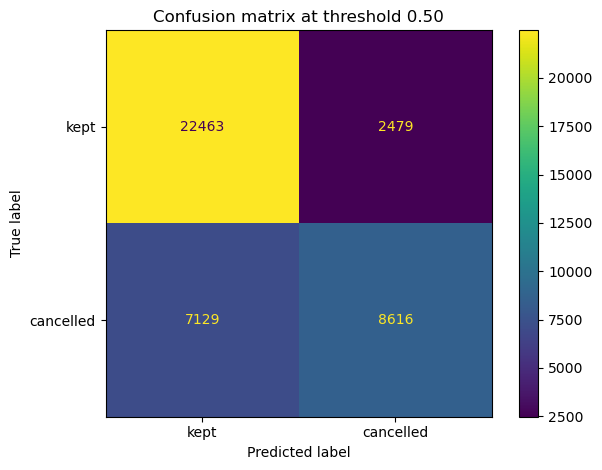


threshold = 0.70
[[24748   194]
 [11117  4628]]
              precision    recall  f1-score   support

           0      0.690     0.992     0.814     24942
           1      0.960     0.294     0.450     15745

    accuracy                          0.722     40687
   macro avg      0.825     0.643     0.632     40687
weighted avg      0.794     0.722     0.673     40687



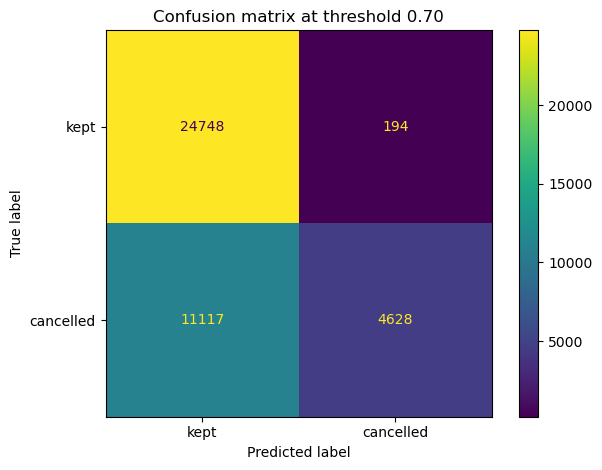

In [11]:
for threshold in [0.50, 0.70]:
    flagged = (prob_h >= threshold).astype(int)                   # 1 = treat as a likely cancellation
    print(f"\nthreshold = {threshold:.2f}")
    print(confusion_matrix(yh_valid, flagged))                    # rows: the truth; columns: the decision
    print(classification_report(yh_valid, flagged, digits=3))
    ConfusionMatrixDisplay.from_predictions(yh_valid, flagged, display_labels=["kept", "cancelled"])
    plt.title(f"Confusion matrix at threshold {threshold:.2f}")
    plt.tight_layout()
    plt.savefig(RESULTS / f"confusion_matrix_at_threshold_{threshold:.2f}.png",
                dpi=160, bbox_inches="tight")
    plt.show()

### Question 12 — Summarize the ranking: ROC and PR

Two numbers summarize the ranking without choosing any threshold. ROC AUC is the chance that a random defaulter scores higher than a random payer. Average precision (PR AUC) focuses on the positive class; guessing scores the positive rate, so it is the more honest number when positives are rare.

**Read the code.**

- `np.linspace(0.05, 0.95, 19)` gives 19 thresholds, and the loop records precision and recall at each one. `zero_division=0` covers a threshold at which nothing is flagged.
- `roc_auc_score` and `average_precision_score` summarize the ranking without choosing any threshold.
- `RocCurveDisplay.from_predictions` and `PrecisionRecallDisplay.from_predictions` draw the two curves from the truth and the probabilities.

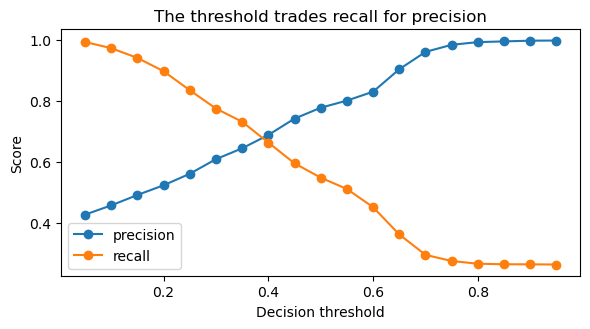

ROC AUC: 0.824
PR AUC (average precision): 0.786  against 0.387 for guessing


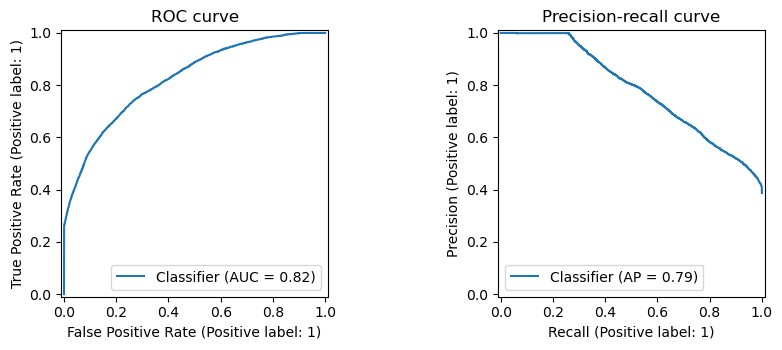

In [12]:
# Precision and recall at 19 thresholds from 0.05 to 0.95.
thresholds = np.linspace(0.05, 0.95, 19)
precisions, recalls = [], []
for t in thresholds:
    flagged = (prob_h >= t).astype(int)
    precisions.append(precision_score(yh_valid, flagged, zero_division=0))
    recalls.append(recall_score(yh_valid, flagged))

plt.figure(figsize=(6, 3.4))
plt.plot(thresholds, precisions, marker="o", label="precision")
plt.plot(thresholds, recalls, marker="o", label="recall")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("The threshold trades recall for precision")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "the_threshold_trades_recall_for_precision.png", dpi=160, bbox_inches="tight")
plt.show()

# Two summaries of the ranking that need no threshold at all.
print("ROC AUC:", round(roc_auc_score(yh_valid, prob_h), 3))
print("PR AUC (average precision):", round(average_precision_score(yh_valid, prob_h), 3),
      " against", round(yh_valid.mean(), 3), "for guessing")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
RocCurveDisplay.from_predictions(yh_valid, prob_h, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(yh_valid, prob_h, ax=axes[1])
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.savefig(RESULTS / "precision_recall_curve.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** Always answering *kept* is 61.3% accurate on 2017. Logistic regression scores accuracy 0.764 and ROC AUC 0.824, the random forest 0.770 and 0.841. The logistic model's three thresholds trade recall for precision: 0.61 and 0.77 at 0.30, 0.78 and 0.55 at 0.50, 0.96 and 0.29 at 0.70.

The histogram shows why the choice matters. 37.4% of bookings sit between 0.3 and 0.7, where kept and cancelled overlap, and a tower of cancelled bookings sits near 1.0: the 4,126 non-refundable bookings of 2017, 99.8% of which were cancelled. At 0.50 the hotel would flag 11,095 bookings and catch 8,616 of the 15,745 cancellations, but 2,479 of the flagged guests would arrive to a resold room. At 0.70 only 194 would, and it catches 4,628. ROC AUC 0.824 and average precision 0.786, against 0.387 for guessing, say the ranking is useful, so the threshold is a business decision about which mistake costs more.

**Checkpoint: before you move on**

- On 2017, the majority baseline scores 0.613; logistic regression 0.764 accuracy and 0.824 ROC AUC.
- At a threshold of 0.50, 2,479 flagged bookings are kept; at 0.70, only 194 are.
- ROC AUC 0.824, and average precision 0.786 against 0.387 for guessing.

## Part D — Tune with cross-validation, then test once

**Goal.** Choose settings by cross-validation on the training rows, then open the test set exactly once.

*Questions 13–14 · Data: Telco customer churn*

### Question 13 — Tune with cross-validation

Back to Lab 1's telecom customers, now to predict who leaves (`Churn`). The column lists come from the data types, and the test rows are set aside *first*, before anything is fitted, so no step of the search can see them. Inside the training rows, five-fold cross-validation scores every combination of `C` (regularization strength) and `class_weight`, then the grid search refits the winning combination on all training rows.

**Read the code.**

- The Telco table gets Lab 1's repair of `TotalCharges`, and `drop(columns=["customerID", "Churn"])` removes the identifier and the label from the features.
- The test customers are split off first and stay closed until Question 14.
- `GridSearchCV` tries every combination in `param_grid`. The name `model__C` means "the setting `C` of the pipeline step called `model`": two underscores join a step's name to one of its settings.
- Each combination is scored by five-fold cross-validation on the training customers, with the whole pipeline refitted inside every fold.
- `search.cv_results_` holds one row per combination, with the mean and the spread of its five scores.

4 numeric and 15 text columns; 26.5% of customers left


cross-validated ROC AUC ranges from 0.841 to 0.844 ; typical fold-to-fold spread 0.015


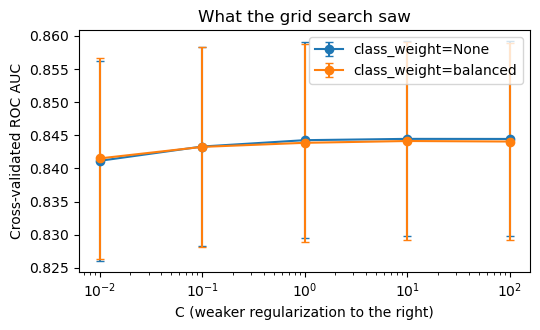

In [13]:
churn = pd.read_csv(DATA / "supervised/telco_customer_churn/telco_customer_churn.csv")
churn["TotalCharges"] = pd.to_numeric(churn["TotalCharges"], errors="coerce").fillna(0)  # Lab 1's repair
X_c = churn.drop(columns=["customerID", "Churn"])
y_c = (churn["Churn"] == "Yes").astype(int)
c_num = X_c.select_dtypes(include="number").columns.tolist()
c_cat = X_c.select_dtypes(exclude="number").columns.tolist()
print(len(c_num), "numeric and", len(c_cat), "text columns;", f"{y_c.mean():.1%} of customers left")

# The test rows are set aside first, and stay closed until Question 14.
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.25, random_state=42,
                                                        stratify=y_c)

# Try every combination of C and class_weight with five-fold cross-validation on the training rows only.
search = GridSearchCV(
    Pipeline([("preprocess", make_preprocess(c_num, c_cat)),
              ("model", LogisticRegression(max_iter=3000))]),
    param_grid={
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],         # smaller C = stronger regularization
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
search.fit(Xc_train, yc_train)

cv_table = pd.DataFrame(search.cv_results_)                  # one row per combination
print("cross-validated ROC AUC ranges from", round(cv_table["mean_test_score"].min(), 3),
      "to", round(cv_table["mean_test_score"].max(), 3),
      "; typical fold-to-fold spread", round(cv_table["std_test_score"].mean(), 3))

plt.figure(figsize=(5.5, 3.4))
for weight, group in cv_table.groupby(cv_table["param_model__class_weight"].astype(str)):
    plt.errorbar(group["param_model__C"].astype(float), group["mean_test_score"],
                 yerr=group["std_test_score"], marker="o", capsize=3, label=f"class_weight={weight}")
plt.xscale("log")
plt.xlabel("C (weaker regularization to the right)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("What the grid search saw")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "what_the_grid_search_saw.png", dpi=160, bbox_inches="tight")
plt.show()

**What to look for.** The curve is flat: every setting scores between 0.841 and 0.844, while the error bars, one standard deviation across five folds, are about 0.015 wide. This table does not care much about `C`, and small gaps between settings should not be over-read.

### Question 14 — Open the test set once

Only now is the test set touched, once.

**Read the code.**

- After `fit`, the search object holds the best combination, refitted on all the training customers, so `search.predict_proba` uses that model.
- `search.best_params_` is the winning combination and `search.best_score_` its cross-validated score.
- The test set is scored here and nowhere else.

In [14]:
# search now holds the best setting, refitted on all the training rows. The test set is used once.
test_prob = search.predict_proba(Xc_test)[:, 1]
test_auc = roc_auc_score(yc_test, test_prob)

print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("final test ROC AUC:", round(test_auc, 3), "on", len(yc_test), "customers")

best parameters: {'model__C': 10.0, 'model__class_weight': None}
cross-validated ROC AUC: 0.844
final test ROC AUC: 0.846 on 1761 customers


**What the output shows.** 4 numeric and 15 text columns; 26.5% of the customers left. The search picks `C = 10` without class weights, at a cross-validated ROC AUC of 0.844, then a single test ROC AUC of 0.846 on 1,761 customers. The two agree, as they should when the test rows were sealed from the start. Report the test number once, and do not tune again after seeing it.

**Checkpoint: before you move on**

- Best setting: `C` = 10 without class weights, cross-validated ROC AUC 0.844.
- The final test ROC AUC, 0.846, is reported once, and nothing is tuned after it.

## Part E — Save the models and use them

**Goal.** Save each model with a card, reload it, and use it from a script.

*Questions 15–16 · Data: the two fitted models*

### Question 15 — Save the churn model with a card

A model that exists only inside a running notebook is not finished. `joblib.dump` writes the whole pipeline, preprocessing and estimator together, to one file. A model card written next to it records what the file expects, how well it did, and a typical customer, so someone else can use it safely.

**Read the code.**

- `search.best_estimator_` is the fitted pipeline, preparation and model in one object, and `joblib.dump` writes it to a file.
- `typical` records a typical value for every column: the median of a number column, and the most common value, `mode()[0]`, of a text column.
- The card is an ordinary dictionary, written as text with `json.dumps(card, indent=2)`.
- `model_path.stat().st_size / 1024` is the size of the file in kilobytes.

In [15]:
# The fitted pipeline (preparation and model together) goes to one file ...
final_model = search.best_estimator_
model_path = MODELS / "customer_churn.joblib"
joblib.dump(final_model, model_path)

# ... and a model card records what it expects and how well it tested. The typical customer
# (the median of each number column, the most common value of each text column) lets a script
# fill in any column it is not given.
typical = {c: float(Xc_train[c].median()) if c in c_num else str(Xc_train[c].mode()[0])
           for c in X_c.columns}
card = {
    "task": "predict whether a telecom customer leaves (1 = churned) from the IBM Telco table",
    "features": X_c.columns.tolist(),
    "typical_customer": typical,
    "model": "logistic regression pipeline",
    "best_parameters": search.best_params_,
    "training_rows": int(len(Xc_train)),
    "final_test_roc_auc": round(float(test_auc), 3),
    "decision_threshold": 0.5,
    "scikit_learn_version": sklearn.__version__,
}
(MODELS / "customer_churn_card.json").write_text(json.dumps(card, indent=2))
size_kb = model_path.stat().st_size / 1024
print(f"saved: {model_path.name} ({size_kb:.1f} KB) and customer_churn_card.json")

saved: customer_churn.joblib (8.3 KB) and customer_churn_card.json


### Question 16 — Reload the models and use them

Deployment, in its smallest form, is three lines: load the file, hand it new rows with the same column names, read the predictions. No retraining and no preprocessing code, because the preprocessing travelled inside the file. A real customer's row is the template for the two new ones, so every column the model expects is there. The car-price model is saved the same way and used to price one car at two mileages.

**Read the code.**

- `joblib.load` returns the pipeline exactly as it was saved.
- `template = X_c.iloc[0].to_dict()` copies a real customer's row, so that every column the model expects is present. `{**template, "tenure": 2, ...}` makes a copy of it with a few values replaced.
- `loaded.predict_proba(new_customers)[:, 1]` runs the whole pipeline on the new rows: filling, scaling, encoding and the model.
- The car-price model is saved, reloaded and asked about one car at two mileages in the same way.

In [16]:
# Load the saved model and ask it about two customers. A real customer's row is the template,
# so every column the model expects is there; only the columns that differ are changed.
loaded = joblib.load(model_path)
template = X_c.iloc[0].to_dict()
new_customers = pd.DataFrame([
    {**template, "tenure": 2, "Contract": "Month-to-month", "InternetService": "Fiber optic",
     "PaymentMethod": "Electronic check", "MonthlyCharges": 85.0, "TotalCharges": 170.0},
    {**template, "tenure": 60, "Contract": "Two year", "InternetService": "DSL",
     "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 60.0, "TotalCharges": 3600.0},
])
new_customers["churn_probability"] = loaded.predict_proba(new_customers)[:, 1].round(3)
print(new_customers[["tenure", "Contract", "InternetService", "PaymentMethod",
                     "churn_probability"]].to_string())

# The same for the car-price model: one car, listed at two mileages.
joblib.dump(fitted["linear regression"], MODELS / "used_car_prices.joblib")
pricing = joblib.load(MODELS / "used_car_prices.joblib")
car = {"age": 5, "make": "Toyota", "body_type": "SUV", "drive": "AWD", "fuel_type": "gasoline"}
new_cars = pd.DataFrame([{**car, "mileage_miles": 30_000}, {**car, "mileage_miles": 90_000}])
new_cars["predicted_price"] = pricing.predict(new_cars).round(-2)
print(new_cars[["make", "body_type", "age", "mileage_miles", "predicted_price"]].to_string())

   tenure        Contract InternetService              PaymentMethod  churn_probability
0       2  Month-to-month     Fiber optic           Electronic check              0.305
1      60        Two year             DSL  Bank transfer (automatic)              0.004
     make body_type  age  mileage_miles  predicted_price
0  Toyota       SUV    5          30000          36700.0
1  Toyota       SUV    5          90000          25900.0


The script `all_experiments/lab02_supervised_workflow/predict_churn.py` does the same job from the terminal, so anyone with the model file can use it without opening a notebook. Any column it is not given takes the typical customer's value from the card:

```bash
python all_experiments/lab02_supervised_workflow/predict_churn.py --tenure 2 --contract Month-to-month --monthly 85
```

**What the output shows.** `customer_churn.joblib` is about 8 KB and holds the imputers, the scaler, the encoder and the classifier. The reloaded model gives a new month-to-month fibre customer paying by electronic check a 30.5% chance of leaving, and a five-year customer on a two-year contract 0.4%. The car-price model prices a five-year-old Toyota SUV at \$36,700 with 30,000 miles and \$25,900 with 90,000: the mileage coefficient from Question 4, at work.

**Checkpoint: before you move on**

- `customer_churn.joblib` and its card are in `models/`, beside `used_car_prices.joblib`.
- `predict_churn.py` prints a churn probability from the terminal.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 17 — Save the evidence

**Read the code.**

- `rows` collects one dictionary per result, and `pd.DataFrame(rows)` turns the list into a table. A result with no `test` entry gets a blank there.
- `to_csv(..., index=False)` writes the table without row numbers.
- The last lines list the files in the results folder and the models this lab saved.

**Read the code.**

- `rows` collects one dictionary per result, and `pd.DataFrame(rows)` turns the list into a table. A result with no `test` entry gets a blank there.
- `to_csv(..., index=False)` writes the table without row numbers.
- The last lines list the files in the results folder and the models this lab saved.

In [17]:
# One row per model and dataset, collected from the parts above.
rows = []
for name, pred in predictions.items():
    rows.append({"part": "A", "dataset": "used_cars", "model": name, "metric": "mae",
                 "validation": mean_absolute_error(y_valid, pred)})
rows.append({"part": "B", "dataset": "hotel_bookings", "model": "logistic (shuffled split)",
             "metric": "roc_auc",
             "validation": roc_auc_score(yr_valid, shuffled.predict_proba(Xr_valid)[:, 1])})
for name, s in scores.items():
    rows.append({"part": "C", "dataset": "hotel_bookings", "model": f"{name} (date split)",
                 "metric": "roc_auc", "validation": s["roc_auc"]})
rows.append({"part": "D", "dataset": "telco_customer_churn", "model": f"logistic {search.best_params_}",
             "metric": "roc_auc", "validation": search.best_score_, "test": test_auc})
pd.DataFrame(rows).round(4).to_csv(RESULTS / "metrics.csv", index=False)
monthly.round(4).to_csv(RESULTS / "monthly_cancellations.csv")

print("Saved:", sorted(p.name for p in RESULTS.iterdir()))
model_files = [p.name for p in MODELS.iterdir()
               if p.name.startswith(("customer_churn", "used_car_prices"))]
print("Model files:", sorted(model_files))

Saved: ['a_threshold_is_a_vertical_line_through_this_picture.png', 'confusion_matrix_at_threshold_0.50.png', 'confusion_matrix_at_threshold_0.70.png', 'metrics.csv', 'monthly_cancellations.csv', 'precision_recall_curve.png', 'ridge_residual_plot.png', 'the_threshold_trades_recall_for_precision.png', 'trained_on_the_past_scored_on_2017.png', 'two_models_two_metrics_one_date_split.png', 'what_the_grid_search_saw.png', 'what_the_linear_model_learned.png']
Model files: ['customer_churn.joblib', 'customer_churn_card.json', 'used_car_prices.joblib']


## Try it yourself

The residuals of Question 5 fan out, and 377 cars get a negative price. Refit Part A's linear regression on the logarithm of the price, turn its predictions back into dollars with `np.exp`, and compare the MAE, $R^2$ and the residual spread by quarter with Questions 3 and 5.

Attempt it in the cell below before reading the solution.

### Question 18 — Try it yourself, and a decision memo

In [18]:
# Your work here

## Decision memo

Choose the threshold above which the hotel treats a 2017 booking as a likely cancellation and resells its room, in a setting where *walking* a guest (finding them a room at another hotel, because theirs was resold) costs about twice the revenue lost on an empty room. State what happens to the confusion matrix when the threshold is lowered, and name the validation evidence from Part C that supports your choice.

Write your own memo first; a model answer follows the solution.

**Threshold chosen:**

**Evidence used:**

**What lowering the threshold does:**

### One solution

Part A's model on the logarithm of the price; on that scale each coefficient is a percentage change.

### Question 19 — One solution

**Read the code.**

- The pipeline is the one from Question 3, fitted to `np.log(y_train)` instead of `y_train`. `np.exp` turns its predictions back into dollars before any score is computed.
- `(log_pred < 0).sum()` counts negative prices. The number e raised to any power is positive, so there are none.
- `pd.qcut` and `groupby(...).std()` repeat the residual check of Question 5.
- On the log scale a coefficient is a multiplier. Dividing it by the column's standard deviation undoes the scaling, and `np.exp` turns the result into "times this much for one more year".

**Read the code.**

- The pipeline is the one from Question 3, fitted to `np.log(y_train)` instead of `y_train`. `np.exp` turns its predictions back into dollars before any score is computed.
- `(log_pred < 0).sum()` counts negative prices. The number e raised to any power is positive, so there are none.
- `pd.qcut` and `groupby(...).std()` repeat the residual check of Question 5.
- On the log scale a coefficient is a multiplier. Dividing it by the column's standard deviation undoes the scaling, and `np.exp` turns the result into "times this much for one more year".

In [19]:
# Part A's linear regression, trained on the logarithm of the price;
# exp turns its predictions back into dollars.
log_model = Pipeline([("preprocess", make_preprocess(num_cols, cat_cols)), ("model", LinearRegression())])
log_model.fit(X_train, np.log(y_train))
log_pred = np.exp(log_model.predict(X_valid))

print("log-price model: MAE", round(mean_absolute_error(y_valid, log_pred)),
      " R2", round(r2_score(y_valid, log_pred), 3), " prices below zero:", int((log_pred < 0).sum()))
quarter_log = pd.qcut(log_pred, 4, labels=["cheapest", "second", "third", "dearest"])
print("spread of the residuals by quarter of predicted price:")
print((y_valid - log_pred).groupby(quarter_log, observed=True).std().round(0).to_string())

# On the log scale a coefficient is a percentage:
# one more year, or 10,000 more miles, multiplies the price by:
log_coefs = pd.Series(log_model.named_steps["model"].coef_,
                      index=log_model.named_steps["preprocess"].get_feature_names_out())
per_year = np.exp(log_coefs["num__age"] / X_train["age"].std())
per_10k_miles = np.exp(log_coefs["num__mileage_miles"] / X_train["mileage_miles"].std() * 10_000)
print(f"one more year: x{per_year:.3f}   10,000 more miles: x{per_10k_miles:.3f}")

log-price model: MAE 7695  R2 0.611  prices below zero: 0


spread of the residuals by quarter of predicted price:
cheapest     7763.0
second       8161.0
third       11584.0
dearest     21658.0
one more year: x0.971   10,000 more miles: x0.931


**What it shows.** The log-price model misses by \$7,695 instead of \$9,009, explains 61.1% of the variation in dollars instead of 57.5%, and gives no car a negative price. The residuals still widen with price (from \$7,763 to \$21,658 by quarter), because a 10% miss on a dear car is more dollars, but the model now treats price as multiplicative: each extra year multiplies it by 0.971 and each extra 10,000 miles by 0.931, whatever the car. A transformed label is often the cheapest fix for a fan of residuals.

### A model decision memo

**Threshold chosen:** 0.65 for the cancellation model.

**Evidence used (Part C):** at the default 0.50 the hotel would resell the rooms of 2,479 guests who then arrive, while missing 7,129 cancellations; at 0.70 only 194 guests would be walked, but 11,117 cancelled rooms would stand empty. If walking a guest costs twice an empty room, a sweep of thresholds from 0.05 to 0.95 makes 0.65 the cheapest, with 10,065 empty rooms and 611 walked guests. It sits close to the break-even probability, $2/(2+1)=0.67$, above which a booking is more likely to cancel than the walking cost justifies.

**What lowering the threshold does:** it moves the vertical line left through the histogram. More bookings are flagged, so fewer cancelled rooms stand empty but more guests arrive to find their room resold: recall goes up and precision down. The right threshold is a statement about costs: change the two-to-one ratio and the answer changes.